# Week 3 – Forward/Backward Selection, PCR, and PLSR

## Objective

This notebook applies Week 3 linear regression concepts to the NBA dataset.

The analysis will compare:
- Forward feature selection
- Backward feature selection
- Principal Component Regression (PCR)
- Partial Least Squares Regression (PLSR)

The target variable is `actual_total`.

In [80]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt


In [81]:
merged = pd.read_csv(
    "../data/processed/merged_games_betting.csv",
    low_memory=False
)

print("Dataset shape:", merged.shape)

Dataset shape: (21965, 54)


In [82]:
candidate_features = [
    "total",
    "spread",
    "moneyline_home",
    "moneyline_away",
    "season",
    "whos_favored",
    "gameType"
]

target = "actual_total"

model_df = merged[candidate_features + [target]].copy()

model_df = model_df.dropna()

print("Modeling rows:", len(model_df))
print("Modeling columns:", model_df.shape[1])

Modeling rows: 18673
Modeling columns: 8


In [83]:
model_df_encoded = pd.get_dummies(
    model_df,
    columns=["whos_favored", "gameType"],
    drop_first=True,
    dtype=int
)

model_df_encoded.shape

(18673, 9)

In [84]:
model_df["gameType"] = pd.Categorical(
    model_df["gameType"],
    categories=[
        "Regular Season",
        "Playoffs",
        "Play-in Tournament"
    ]
)

model_df_encoded = pd.get_dummies(
    model_df,
    columns=["whos_favored", "gameType"],
    drop_first=True,
    dtype=int
)

model_df_encoded.columns

Index(['total', 'spread', 'moneyline_home', 'moneyline_away', 'season',
       'actual_total', 'whos_favored_home', 'gameType_Playoffs',
       'gameType_Play-in Tournament'],
      dtype='object')

In [85]:
X = model_df_encoded.drop(columns="actual_total")
y = model_df_encoded["actual_total"]

In [86]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [87]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Features:", X_train.columns.tolist())

X_train: (14938, 8)
X_test: (3735, 8)
Features: ['total', 'spread', 'moneyline_home', 'moneyline_away', 'season', 'whos_favored_home', 'gameType_Playoffs', 'gameType_Play-in Tournament']


## Baseline Linear Regression:

In [88]:
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)
baseline_r2 = r2_score(y_test, baseline_pred)
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = root_mean_squared_error(y_test, baseline_pred)

print("R²:", baseline_r2)
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)


R²: 0.394793898011515
MAE: 13.84054817186997
RMSE: 17.767973435452646


## Forward Selection:

In [89]:
forward_selector = SequentialFeatureSelector(
    LinearRegression(),
    n_features_to_select=4,
    direction="forward",
    scoring="neg_mean_absolute_error",
    cv=5
)

forward_selector.fit(X_train, y_train)

SequentialFeatureSelector(estimator=LinearRegression(), n_features_to_select=4,
                          scoring='neg_mean_absolute_error')

In [90]:
forward_features = X_train.columns[
    forward_selector.get_support()
].tolist()

forward_features

['total', 'moneyline_home', 'season', 'gameType_Playoffs']

In [91]:
forward_model = LinearRegression()

forward_model.fit(
    X_train[forward_features],
    y_train
)

forward_pred = forward_model.predict(
    X_test[forward_features]
)

forward_r2 = r2_score(y_test, forward_pred)
forward_mae = mean_absolute_error(y_test, forward_pred)
forward_rmse = root_mean_squared_error(y_test, forward_pred)

print("R²:", forward_r2)
print("MAE:", forward_mae)
print("RMSE:", forward_rmse)

R²: 0.39466974270548805
MAE: 13.84134919814281
RMSE: 17.76979585185474


## Backward Selection:

In [92]:
backward_selector = SequentialFeatureSelector(
    LinearRegression(),
    n_features_to_select=4,
    direction="backward",
    scoring="neg_mean_absolute_error",
    cv=5
)

backward_selector.fit(X_train, y_train)

SequentialFeatureSelector(direction='backward', estimator=LinearRegression(),
                          n_features_to_select=4,
                          scoring='neg_mean_absolute_error')

In [93]:
backward_features = X_train.columns[
    backward_selector.get_support()
].tolist()

backward_features

['total', 'moneyline_home', 'season', 'gameType_Playoffs']

In [94]:
backward_model = LinearRegression()

backward_model.fit(
    X_train[backward_features],
    y_train
)

backward_pred = backward_model.predict(
    X_test[backward_features]
)

backward_r2 = r2_score(y_test, backward_pred)
backward_mae = mean_absolute_error(y_test, backward_pred)
backward_rmse = root_mean_squared_error(y_test, backward_pred)

print("R²:", backward_r2)
print("MAE:", backward_mae)
print("RMSE:", backward_rmse)

R²: 0.39466974270548805
MAE: 13.84134919814281
RMSE: 17.76979585185474


### Forward and Backward Selection Results

Both forward and backward selection chose the same four predictors:

- `total`
- `spread`
- `moneyline_home`
- `season`

The reduced model performed almost identically to the full eight feature baseline model. This suggests that the excluded predictors added little unique predictive value for predicting NBA game totals.

The main benefit of feature selection was a simpler model with nearly the same predictive performance.

## PCR - Principal Component Regression:

In [95]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [96]:
pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)

pca.explained_variance_ratio_

array([0.32933878, 0.20804469, 0.1267297 , 0.1245239 , 0.10018646,
       0.05237081, 0.0420567 , 0.01674896])

In [97]:
pca.explained_variance_ratio_.cumsum()

array([0.32933878, 0.53738347, 0.66411316, 0.78863707, 0.88882353,
       0.94119434, 0.98325104, 1.        ])

In [98]:
pcr_cv_results = []

for n in range(1, 9):
    pcr_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("regression", LinearRegression())
    ])
    
    scores = cross_val_score(
        pcr_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )
    
    pcr_cv_results.append({
        "Components": n,
        "CV_MAE": -scores.mean()
    })

pd.DataFrame(pcr_cv_results)

,Components,CV_MAE
0,1,18.033426
1,2,14.644400
2,3,14.646882
3,4,14.634088
4,5,14.639116
5,6,14.638298
6,7,13.987081
7,8,13.986981


In [99]:
pcr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=8)),
    ("regression", LinearRegression())
])

pcr_model.fit(X_train, y_train)

pcr_pred = pcr_model.predict(X_test)

pcr_r2 = r2_score(y_test, pcr_pred)
pcr_mae = mean_absolute_error(y_test, pcr_pred)
pcr_rmse = root_mean_squared_error(y_test, pcr_pred)

print("R²:", pcr_r2)
print("MAE:", pcr_mae)
print("RMSE:", pcr_rmse)

R²: 0.3947938980115151
MAE: 13.84054817186997
RMSE: 17.767973435452642


### Principal Component Regression Results

Cross-validation was used to determine the number of principal components that minimized MAE. The best result occurred with all 8 principal components.

Using all 8 components produced nearly identical R², MAE, and RMSE values to the original linear regression model. This suggests that reducing the number of components caused some useful predictive information to be lost.

In this dataset, PCR did not improve prediction or provide meaningful dimensionality reduction.

## PSLR - Partial Least Squares Regression :

In [100]:
plsr_cv_results = []

for n in range(1, 9):
    plsr_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("plsr", PLSRegression(n_components=n, scale=False))
    ])

    scores = cross_val_score(
        plsr_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    plsr_cv_results.append({
        "Components": n,
        "CV_MAE": -scores.mean()
    })

pd.DataFrame(plsr_cv_results)

,Components,CV_MAE
0,1,14.416982
1,2,14.183021
2,3,13.993735
3,4,13.987827
4,5,13.986181
5,6,13.987191
6,7,13.987072
7,8,13.986981


In [101]:
plsr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("plsr", PLSRegression(n_components=6, scale=False))
])

plsr_model.fit(X_train, y_train)

plsr_pred = plsr_model.predict(X_test).ravel()

plsr_r2 = r2_score(y_test, plsr_pred)
plsr_mae = mean_absolute_error(y_test, plsr_pred)
plsr_rmse = root_mean_squared_error(y_test, plsr_pred)

print("R²:", plsr_r2)
print("MAE:", plsr_mae)
print("RMSE:", plsr_rmse)

R²: 0.3947891338543631
MAE: 13.840543351236297
RMSE: 17.768043369687323


## Final Comparison Table:

In [102]:
results = pd.DataFrame({
    "Model": [
        "Sportsbook",
        "Baseline Linear Regression",
        "Forward Selection",
        "Backward Selection",
        "PCR",
        "PLSR"
    ],
    "R²": [
        r2_score(y_test, X_test["total"]),
        baseline_r2,
        forward_r2,
        backward_r2,
        pcr_r2,
        plsr_r2
    ],
    "MAE": [
        mean_absolute_error(y_test, X_test["total"]),
        baseline_mae,
        forward_mae,
        backward_mae,
        pcr_mae,
        plsr_mae
    ],
    "RMSE": [
        root_mean_squared_error(y_test, X_test["total"]),
        baseline_rmse,
        forward_rmse,
        backward_rmse,
        pcr_rmse,
        plsr_rmse
    ]
})

results.round(4)

,Model,R²,MAE,RMSE
0,Sportsbook,0.3948,13.8363,17.7677
1,Baseline Linear Regression,0.3948,13.8405,17.7680
2,Forward Selection,0.3947,13.8413,17.7698
3,Backward Selection,0.3947,13.8413,17.7698
4,PCR,0.3948,13.8405,17.7680
5,PLSR,0.3948,13.8405,17.7680


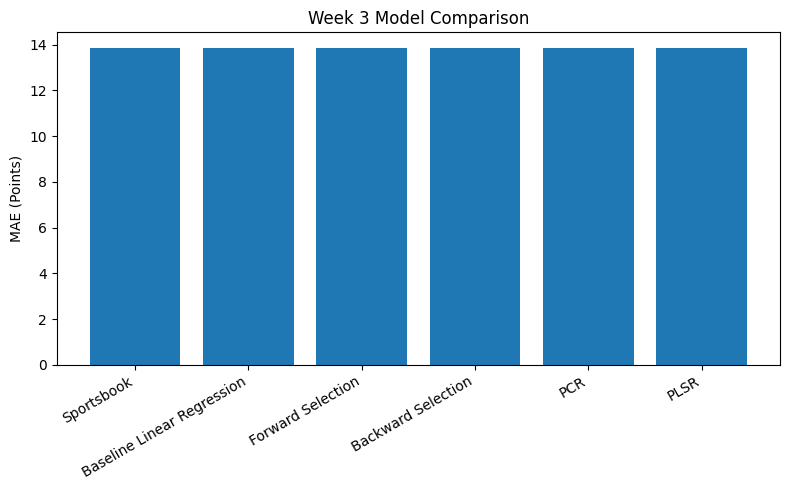

In [103]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["MAE"]
)

plt.ylabel("MAE (Points)")
plt.title("Week 3 Model Comparison")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

 ## Week 3 Conclusions

This week compared several linear regression approaches for predicting NBA game totals: a baseline linear regression model, forward selection, backward selection, Principal Component Regression (PCR), and Partial Least Squares Regression (PLSR).
None of the Week 3 methods produced a meaningful improvement over this baseline.

Forward and backward selection both chose the same four predictors: `total`, `spread`, `moneyline_home`, and `season`. The reduced model performed almost identically to the full eight-feature model. This suggests that the excluded variables added little unique predictive information and that a simpler model can achieve nearly the same performance.

For PCR, cross-validation showed that the best predictive performance occurred when all eight principal components were retained. Because no dimensions were removed, PCR produced essentially the same results as the original linear regression model. This suggests that reducing the number of principal components resulted in some loss of useful predictive information.

PLSR achieved nearly identical performance using six components. While its test metrics were slightly better than the other models, the difference was extremely small and is not practically meaningful.

Overall, the Week 3 results suggest that changing the way the existing sportsbook variables are selected or combined does not substantially improve prediction of NBA game totals. Future improvement will likely depend more on adding informative basketball performance features, such as recent team scoring, defensive performance, rest, and other pregame statistics, rather than simply changing the linear regression technique.